# Matching scRNA cells to scDNA clones with clonealign

clonealign assigns each cell of a single-cell RNA sequencing (scRNA) data set to one of the clones found by single-cell DNA sequencing (scDNA) of the same tumor (Campbell et al., 2019).
It assumes that the expression of a gene in a cell is proportional to the copy number of the gene in the clone of the cell.
In this tutorial we load a pregrown tumor, sequence its cells with scDNA and scRNA, find the clones of the scDNA, assign the scRNA cells to them with clonealign and score the assignments against the ground truth.
clonealign runs from its own conda environment, `iscc-clonealign`, which contains R, TensorFlow and the clonealign package.
The notebook runs in about twenty minutes on a laptop.

In [1]:
%matplotlib inline
import os, tempfile

import numpy as np
import pandas as pd
from IPython.display import Image
from scipy.cluster.hierarchy import fcluster, linkage

from iscc import pregrown
from iscc.sample import Resection
from iscc.data import scDNA, scRNA
from iscc.data.human import HumanGenomeLayer
from iscc.integrations import biological_types

os.chdir(tempfile.mkdtemp())        # the data and the outputs of the tool go to a scratch directory

## Load a tumor

We load `cin`, one of the [pregrown tumors](https://pedrofale.github.io/iscc/reference/#pregrown-tumors), a chromosomally unstable tumor of about 200,000 cancer cells on a 1 cm field, grown with the immune cells of the paper's regime in the stroma.
96% of its cancer cells have a doubled genome, and the clones differ mostly in copy number.
Its genome has one segment per chromosome arm, and it carries the expression layer of the `iscc` paper, with gene programs, the epithelium as the cell of origin and the per-gene dosage that the paper fitted to TCGA breast tumors.
Under this dosage law, the expression of a gene at total copy number C is its baseline times 1 + s (C/2 - 1), where the sensitivity s of each gene is drawn from a normal distribution with mean 0.86 and standard deviation 0.61 and clipped to the interval from 0 to 1, and copy numbers above 8 count as 8.
A gene with a sensitivity of 1 follows proportional dosage, the assumption of clonealign, and the expression of a gene with a sensitivity of 0 does not change with its copy number.

In [2]:
tumor = pregrown.cin()
print(f"{tumor.get_cancer_size():,} cancer cells of {tumor.get_tumor_size():,} cells after {tumor.time:.0f} generations")

sensitivity = tumor.programs.dosage_sensitivity
print(f"genes with proportional dosage: {np.mean(sensitivity == 1):.0%}, "
      f"genes whose expression ignores copy number: {np.mean(sensitivity == 0):.0%}")

200,045 cancer cells of 586,471 cells after 284 generations
genes with proportional dosage: 41%, genes whose expression ignores copy number: 7%


## Sequence the cells with scDNA and scRNA

As in [the HMMcopy tutorial](tool_hmmcopy.ipynb), we dissociate the specimen, enrich the suspension for epithelial cells by keeping 90% of the cancer and epithelial cells and 5% of the stromal and immune cells, and sequence 400 cells with the DLP+ preset of the [`scDNA`](https://pedrofale.github.io/iscc/reference/scDNA/) assay.
We measure the cancer cells of the same suspension with the 10x preset of the [`scRNA`](https://pedrofale.github.io/iscc/reference/scRNA/) assay.
A study keeps the cancer cells after annotating the cell types, and here we take the cell types from the ground truth.

In [3]:
specimen = Resection(tumor)
cells = specimen.dissociate(max_cells=3000, layers=["scdna", "scrna"],
                            recovery_probs={"cancer": 0.9, "epithelial": 0.9, "stromal": 0.05,
                                            "immune": 0.05, "myeloid": 0.05, "bplasma": 0.05},
                            seed=0)
cell_type = pd.Series(biological_types(cells["cell_type"]["cell_id"]), index=cells["cell_type"].index)

dna = scDNA(n_cells=400, platform="dlp", doublet_rate=0.0, seed=1).run(cells)
rna = scRNA(protocol="10x", seed=2).run(cells, cell_subset=cell_type.index[cell_type == "cancer"])
counts = rna.observed_counts                               # cells x genes
print("scDNA cells:", cell_type[dna.cells].value_counts().to_dict())
print(f"scRNA: {counts.shape[0]:,} cancer cells, {counts.shape[1]:,} genes, "
      f"{counts.sum(axis=1).median():,.0f} UMIs per cell (median)")

scDNA cells: {'cancer': 351, 'stromal': 24, 'immune': 13, 'epithelial': 12}
scRNA: 2,594 cancer cells, 6,001 genes, 3,997 UMIs per cell (median)


## Find the clones of the scDNA

A study finds the clones of a scDNA run by calling copy number in every cell, for example with [HMMcopy](tool_hmmcopy.ipynb), and clustering the cells by their copy number profiles.
At DLP+ depth a shortcut is enough here.
We average the read count of each cell over each segment of the genome, which is a chromosome arm, divide it by the mean of the cell and multiply it by two, which gives the copy number of each arm relative to a diploid genome.
We cluster the cells by average linkage on the sum of the absolute differences between these profiles, and cut the tree at a distance of 5 copies.
We keep the clusters of at least 10 cells, except the cluster whose median profile is flat, which contains the normal cells.
clonealign normalizes the expected expression of a clone over the genes, so it needs copy number only up to a factor per clone, and we give it the mean relative copy number of each clone.

In [4]:
segment = dna.to_anndata().var["segment"]                  # the segment of every gene
depth = dna.coverage.T.groupby(segment.values).mean().T    # cells x segments
relative = 2 * depth.div(depth.mean(axis=1), axis=0)
tree = linkage(relative.values, method="average", metric="cityblock")
cluster = pd.Series(fcluster(tree, t=5, criterion="distance"), index=relative.index)
size = cluster.value_counts()
flat = relative.groupby(cluster).median().round().eq(2).all(axis=1)
found = size.index[(size >= 10) & ~flat[size.index].to_numpy()]
clones = relative.groupby(cluster).mean().loc[found]
clones.index = [f"dna_{i}" for i in range(1, len(found) + 1)]
clones.round(1).assign(cells=size[found].to_numpy())

,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,cells
dna_1,1.0,2.0,3.0,1.0,2.0,5.1,2.0,1.0,1.9,2.0,...,3.9,1.0,1.0,2.0,2.0,1.9,1.9,2.9,3.9,34
dna_2,1.0,2.0,3.0,1.0,2.0,5.3,2.0,1.0,2.0,2.0,...,4.1,1.0,1.0,2.0,2.0,2.0,1.9,2.9,3.8,28
dna_3,1.0,2.0,3.0,1.0,1.9,4.4,2.0,1.0,1.9,2.5,...,3.4,1.5,1.0,2.0,2.0,1.9,1.9,2.9,3.8,23
dna_4,1.0,2.0,3.0,1.0,2.0,5.1,2.0,1.0,1.6,2.0,...,4.0,1.0,1.0,2.1,2.1,1.9,1.9,2.9,4.0,22
dna_5,1.0,2.0,2.9,1.0,1.9,5.1,2.0,0.9,2.4,2.0,...,4.4,1.0,0.9,2.5,2.0,1.9,1.9,2.4,3.8,22
dna_6,1.0,2.0,3.0,1.0,2.0,4.6,2.0,1.0,1.9,2.0,...,3.1,1.3,1.0,2.0,2.0,1.9,1.9,3.0,4.0,13
dna_7,1.0,2.0,3.0,1.0,2.0,5.0,1.9,1.0,1.9,1.9,...,4.2,0.5,1.0,2.0,2.2,1.8,2.0,2.9,4.4,13
dna_8,1.0,2.3,3.0,1.0,2.1,5.2,2.0,0.5,2.0,2.0,...,3.5,1.0,1.0,2.1,2.1,1.9,1.9,2.7,4.1,10


We found eight clones of at least 10 cells among the cancer cells of the scDNA.
They share most of their copy number changes and differ from one another on a few arms.

## The ground truth

The ground truth holds the true copy number of every scRNA cell.
We put it on the same relative scale and take, for each cell, the scDNA clone whose profile is closest to its own, by the sum of the absolute differences over the arms that clonealign reads.
The likelihood of clonealign needs at least one copy in every clone, so it reads only the arms on which no clone has lost every copy.
The closest clone is the one a perfect assignment would choose.
Not every cell has the profile of a clone found among 400 scDNA cells, and the distance to the closest clone measures how far each cell is from it.

In [5]:
true_cn = cells["cell_cnv"].loc[counts.index]
true_cn = true_cn.T.groupby(segment[true_cn.columns].values).first().T
true_relative = 2 * true_cn.div(true_cn.mean(axis=1), axis=0)
kept = clones.columns[(clones > 0.5).all()]                # the arms on which every clone has a copy
distance = pd.DataFrame(np.abs(true_relative[kept].values[:, None, :] - clones[kept].values[None]).sum(axis=2),
                        index=true_relative.index, columns=clones.index)
closest = distance.idxmin(axis=1)
print(f"distinct true profiles among the scRNA cells: {len(true_relative.round(2).drop_duplicates())}")
pd.DataFrame({"cells": closest.value_counts(),
              "median distance": distance.min(axis=1).groupby(closest).median().round(2)})

distinct true profiles among the scRNA cells: 2215


,cells,median distance
dna_1,674,3.98
dna_2,393,3.23
dna_3,378,4.13
dna_4,216,2.74
dna_5,271,3.17
dna_6,379,4.74
dna_7,129,3.54
dna_8,154,3.76


The 2,594 scRNA cells have 2,215 distinct copy number profiles, as expected in a chromosomally unstable tumor.
The cells closest to each clone differ from it by a median of 2.7 to 4.7 copies summed over the arms, so the clones of the scDNA describe the copy number of the cells only roughly.

## Write the inputs of clonealign

clonealign reads a cells by genes count matrix and a genes by clones copy number matrix.
We write the counts with the writer of the assay and give every gene on the arms that clonealign reads the copy number of its arm in each clone.
To plot the expression along the genome, clonealign also needs the position of each gene, and we use the stretch of its chromosome arm that each growth gene covers in [`HumanGenomeLayer`](https://pedrofale.github.io/iscc/reference/HumanGenomeLayer/).

In [6]:
rna.write("clonealign", write_h5ad=False)                  # clonealign/umis.csv, cells x genes
gene_segment = segment[counts.columns]
genes = gene_segment.index[gene_segment.isin(kept)]
copy_number = clones.T.loc[gene_segment[genes]].set_axis(genes)   # genes x clones
copy_number.to_csv("clonealign/copy_number.csv")
layer = HumanGenomeLayer(tumor)
stretch = layer.grid.set_index("growth_gene").sort_index()    # the stretch of its arm each growth gene covers
pd.DataFrame({"chr": layer.reference.arms["chrom"].str.replace("chr", "").to_numpy()[stretch["arm"]],
              "start_position": stretch["lo"].to_numpy() + 1, "end_position": stretch["hi"].to_numpy()},
             index=counts.columns).loc[genes].to_csv("clonealign/genes.csv")
print(f"{len(genes):,} genes on {len(kept)} of {clones.shape[1]} arms")

5,747 genes on 37 of 39 arms


## Run clonealign

We run clonealign as its documentation does, filtering the genes and cells with `preprocess_for_clonealign` and fitting with `run_clonealign`, which restarts the variational inference from several initializations, all at their defaults.
A cell whose largest assignment probability is below 0.95 stays unassigned.
The variational inference of clonealign is not exactly reproducible on a laptop even with the seed of TensorFlow set, so the counts below can move by a few cells between runs.
We then draw the plot of clonealign (`plot_clonealign`) for the chromosome on which the copy number of the clones varies most, without the random offsets that it adds by default to separate clones with the same copy number.
We draw only the clones to which clonealign assigned cells, so that the two panels of the plot share the colors of the clones.
It shows the copy number of each clone along the chromosome and the expression of the genes in the cells assigned to each clone, scaled per gene and averaged per clone and copy number segment.

In [7]:
%%writefile clonealign/clonealign.R
# clonealign (Campbell et al. 2019) at its defaults
# the Python with TensorFlow of this environment, quiet TensorFlow logs, no terminal control codes
Sys.setenv(RETICULATE_PYTHON = file.path(dirname(dirname(R.home())), "bin", "python"),
           TF_CPP_MIN_LOG_LEVEL = "3", TERM = "dumb")
suppressPackageStartupMessages(library(clonealign))
Y <- as.matrix(read.csv("clonealign/umis.csv", row.names = 1, check.names = FALSE))
L <- as.matrix(read.csv("clonealign/copy_number.csv", row.names = 1, check.names = FALSE))
pp <- preprocess_for_clonealign(Y[, rownames(L)], L)
cat(sprintf("preprocess_for_clonealign kept %d cells and %d genes\n",
            length(pp$retained_cells), length(pp$retained_genes)))

tensorflow::set_random_seed(1)
warned <- character()
fit <- withCallingHandlers(
  run_clonealign(pp$gene_expression_data, pp$copy_number_data, print_elbos = FALSE, verbose = FALSE),
  warning = function(w) {
    warned <<- union(warned, trimws(conditionMessage(w)))
    invokeRestart("muffleWarning")
  })
if (length(warned)) cat("clonealign warned:", warned, sep = "\n")
write.csv(data.frame(cell = pp$retained_cells, clone = fit$clone), "clonealign/clones.csv", row.names = FALSE)

# the expression of the assigned cells along the chromosome whose copy number varies most between clones
suppressPackageStartupMessages(library(SingleCellExperiment))
genes <- read.csv("clonealign/genes.csv", row.names = 1)[pp$retained_genes, ]
spread <- tapply(apply(pp$copy_number_data, 1, sd), genes$chr, mean)
chromosome <- names(which.max(spread))
counts <- t(pp$gene_expression_data)                     # genes x cells
sce <- SingleCellExperiment(list(counts = counts, logcounts = log2(t(t(counts) / colMeans(counts)) + 1)),
                            rowData = genes)
assigned <- fit$clone != "unassigned"
shown <- sort(unique(fit$clone[assigned]))               # the clones with cells, so both panels share their colors
png("clonealign/plot_clonealign.png", width = 9, height = 6, units = "in", res = 100)
suppressMessages(suppressWarnings(print(
  plot_clonealign(sce[, assigned], fit$clone[assigned], pp$copy_number_data[, shown, drop = FALSE], chromosome = chromosome,
                  jitter_cnv = FALSE, ggplot_palette = "Paired"))))
invisible(dev.off())
cat(sprintf("plotted chromosome %s\n", chromosome))

Writing clonealign/clonealign.R


In [8]:
!~/miniconda3/envs/iscc-clonealign/bin/Rscript clonealign/clonealign.R

preprocess_for_clonealign kept 2594 cells and 2867 genes


clonealign warned:
Less than 75% of genes positively correlated with expression - assignment may have failed


plotted chromosome 17


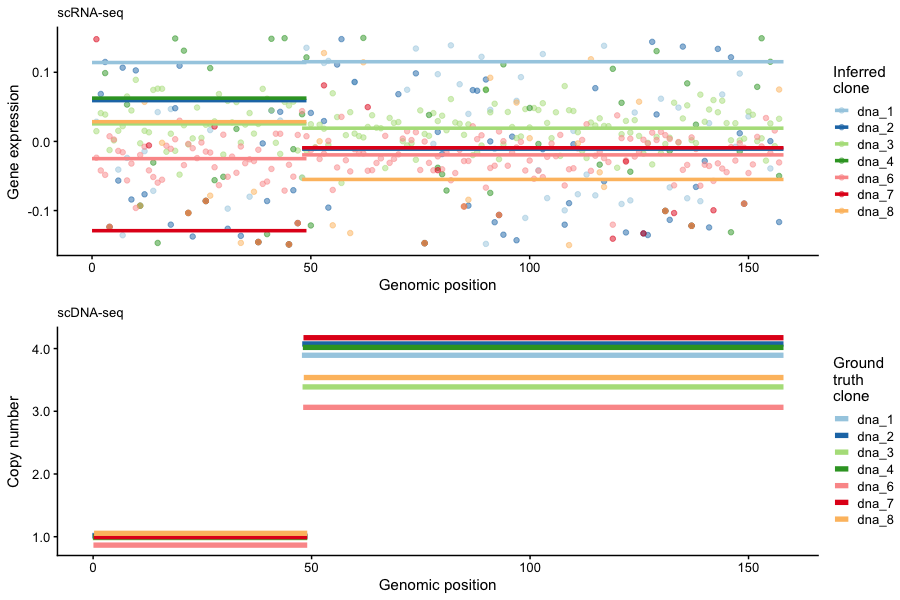

In [9]:
Image("clonealign/plot_clonealign.png", width=800)

On chromosome 17, every clone has about one copy of the short arm, and the copy number of the long arm ranges from 3.1 in dna_6 to 4.2 in dna_7.
On the long arm, the cells assigned to dna_6 had a lower mean expression than those assigned to dna_3, which has 3.4 copies, as dosage predicts.
The expression of the other clones does not follow their copy number, and on the short arm the clones differ in expression although they have the same copy number.
These five clones hold 2 to 20 assigned cells each, so their means are noisy.
The plot groups the cells by the assignment of clonealign, which chose them partly for this agreement, so it shows what the assignment fits and not whether it is correct, which the ground truth tells below.

## Score the assignments

We count a cell as correctly assigned when clonealign assigns it to its closest scDNA clone.
Assigning every cell to the clone that is closest for most cells gives the baseline.

In [10]:
assigned = pd.read_csv("clonealign/clones.csv", index_col="cell")["clone"].reindex(closest.index).fillna("not kept")
print(f"cells assigned to a clone: {assigned.isin(clones.index).mean():.0%}")
print(f"cells assigned to their closest clone: {(assigned == closest).mean():.0%}")
print(f"baseline, every cell to {closest.value_counts().index[0]}: {closest.value_counts(normalize=True).iloc[0]:.0%}")
pd.crosstab(closest.rename("closest clone"), assigned.rename("clonealign"))

cells assigned to a clone: 66%
cells assigned to their closest clone: 18%
baseline, every cell to dna_1: 26%


clonealign,dna_1,dna_2,dna_3,dna_4,dna_6,dna_7,dna_8,unassigned
closest clone,,,,,,,,
dna_1,10,0,202,0,223,0,1,238
dna_2,2,9,95,1,140,0,0,146
dna_3,0,0,235,0,44,0,0,99
dna_4,3,1,45,7,76,0,0,84
dna_5,1,0,41,1,125,0,1,102
dna_6,2,4,56,0,198,2,1,116
dna_7,1,0,22,0,59,0,0,47
dna_8,1,0,49,0,42,0,6,56


clonealign assigned 66% of the cells to a clone, and 18% of all cells to their closest clone, below the 26% of assigning every cell to dna_1.
It also warned that fewer than 75% of the genes are positively correlated with expression, so that the assignment may have failed.
It put 1,652 of its 1,706 assignments into two clones, dna_3 and dna_6, whatever the closest clone of each cell.
Of the cells closest to these two clones, it assigned 235 of 378 to dna_3 and 198 of 379 to dna_6, and of the cells closest to each other clone, at most 10 to that clone.
clonealign assumes that expression is proportional to copy number, while here 59% of the genes are partly or fully buffered, gene programs move expression further and the cells differ from their clones on several arms.
Over the genes of `copy_number.csv`, dna_6 and dna_3 have the flattest profiles, at a mean distance from two copies of 0.54 and 0.56, against 0.58 to 0.65 for the other clones.
The `iscc` paper reports the same pattern: with buffered dosage, clonealign assigned most cells to the clone whose profile was nearest two copies, since the flattest profile fits best when the clones are away from two copies on many arms.

## Make the benchmark harder or easier

The settings of the tumor and of the assays change how hard this benchmark is, and [Shape the tumor](02_shape_the_tumor.ipynb) and [Shape the data](03_shape_the_data.ipynb) show their effects.
The settings of the tumor take effect when we grow a tumor from a configuration instead of loading a pregrown one.

- **Dosage.** A `dosage_sensitivity_mean` of 1 with a `dosage_sensitivity_sd` of 0 gives every gene proportional dosage, the assumption of clonealign, and lower values buffer more genes. The gene programs (`program_params`) and the microenvironment (`microenv_params`) of the expression layer move expression further away from copy number.
- **Clones.** The copy number rate of the cancer cells (`cnv_prob` in `cell_params`) sets how many clones differ in copy number and on how many arms.
- **scRNA.** The depth (`mu_lib`), the overdispersion (`dispersion`), the ambient RNA (`ambient_frac`), the doublets (`doublet_rate`) and the dropout (`dropout_mid`) of the assay set the noise around the dosage signal.
- **scDNA.** Fewer cells or a shallower depth find fewer clones, a lower or higher cut of the tree finds more or fewer clones, and clones called with [HMMcopy](tool_hmmcopy.ipynb) carry the errors of the caller into the copy number that clonealign reads.

The [`scRNA`](https://pedrofale.github.io/iscc/reference/scRNA/), [`scDNA`](https://pedrofale.github.io/iscc/reference/scDNA/) and [`GenotypeTumor`](https://pedrofale.github.io/iscc/reference/GenotypeTumor/) pages document every parameter.